# 5. New method: GRU sequence model

The MLP sees one encounter at a time. A **GRU** (gated recurrent unit) reads the patient's last 24
encounters in order and keeps a memory of them, so it can learn patterns such as
"problem visit → check-up → problem visit".

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False})

In [2]:
from workflow_ml.config import LABELS
from workflow_ml.features import load_table
from workflow_ml.split import patient_folds
from workflow_ml.train import BASE_MODELS, cached_scores, out_of_fold_decisions
from workflow_ml.evaluate import score_table

table = load_table()
folds = patient_folds(table)
y_true = table[list(LABELS)].to_numpy()


def evaluate(name, make_model=None):
    """Out-of-fold scores and metrics for one model (cached after the first run)."""
    scores = cached_scores(name, make_model or BASE_MODELS[name], table, folds)
    decisions = out_of_fold_decisions(scores, y_true, folds)
    return scores, score_table(y_true, scores, decisions).assign(model=name)

## What the network reads
Each row lists the table rows of one encounter's history, oldest first (`-1` = no earlier visit).

In [3]:
from workflow_ml.models.gru import history_windows

history_windows(table.head(8), length=5)

array([[-1, -1, -1, -1,  0],
       [-1, -1, -1,  0,  1],
       [-1, -1,  0,  1,  2],
       [-1,  0,  1,  2,  3],
       [ 0,  1,  2,  3,  4],
       [ 1,  2,  3,  4,  5],
       [ 2,  3,  4,  5,  6],
       [ 3,  4,  5,  6,  7]])

In [4]:
gru_scores, gru_metrics = evaluate("gru")
mlp_scores, mlp_metrics = evaluate("mlp")
print("mean F1  GRU:", gru_metrics["f1"].mean().round(3), "| MLP (no sequence):", mlp_metrics["f1"].mean().round(3))
gru_metrics[["label", "precision", "recall", "f1", "pr_auc", "roc_auc"]].round(3)

mean F1  GRU: 0.684 | MLP (no sequence): 0.606


,label,precision,recall,f1,pr_auc,roc_auc
0,medical_exam,0.535,0.720,0.614,0.595,0.883
1,lab_test,0.819,0.756,0.786,0.883,0.954
2,imaging,0.734,0.692,0.713,0.717,0.925
3,instrument_test,0.753,0.531,0.623,0.677,0.948


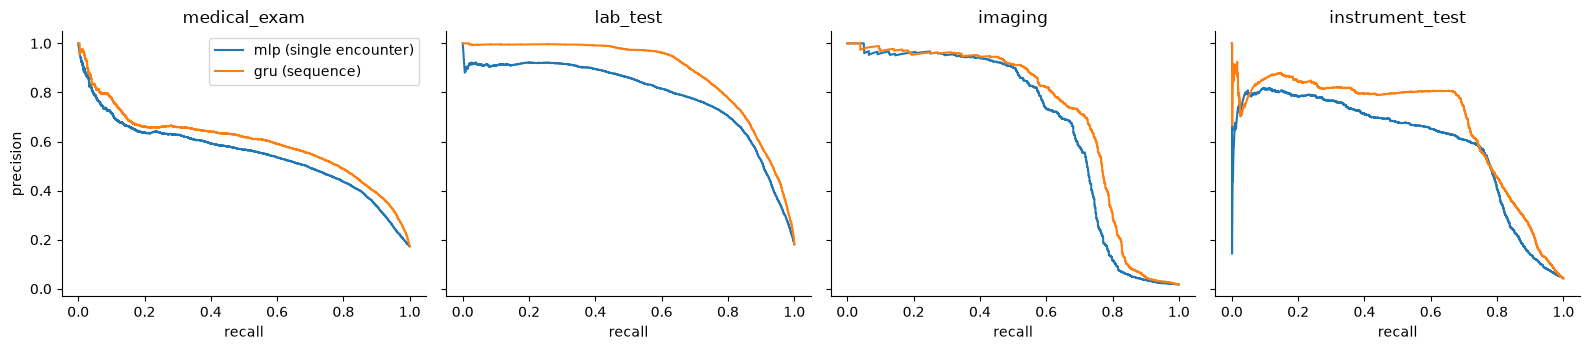

In [5]:
curves = {"mlp (single encounter)": mlp_scores, "gru (sequence)": gru_scores}

from sklearn.metrics import precision_recall_curve

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for column, (label, ax) in enumerate(zip(LABELS, axes)):
    for name, scores in curves.items():
        precision, recall, _ = precision_recall_curve(y_true[:, column], scores[:, column])
        ax.plot(recall, precision, label=name)
    ax.set(title=label, xlabel="recall")
axes[0].set_ylabel("precision")
axes[0].legend()
plt.tight_layout()